# Lesson 25: Sweep Voltammetry

A linear sweep of voltage with time enables the simultaneous probing of current response as a function of both voltage and time. The response is affected by thermodynamics, kinetics, mass transfer, and any secondary processes. The results are therefore rich, but can be extremely complex.

Today's topics:
- Linear sweep voltammetry

**Reference:**
- Ch.6 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE, LARGE
echem.use_style()                       # course-wide graph formatting

# 1. Sweep Voltammetry

A continual sweeping of voltage enables the **current (i)** to be monitored as a function of both **voltage (E)** and **time (t)**. It is very straightforward to set up an experiment for this type of voltammetry, and each experiment has the potential to extract significant amounts of information about the **electrochemical reaction system**. 
Note that the description above highlights the **reaction system**! Experimental results are often sensitive to even minor changes in almost every parameter you can think of. We are usually interested in the thermodynamics or kinetics of an electron transfer reaction. The generalized representation for a half-reaction of interest shows the oxidized species ( $O$ ) being reduced by $n$ electrons to yield the reduced species ( $R$ ):

\begin{equation}
\large O + n e^- \rightleftharpoons R \quad\quad E^{0'}
\end{equation}

The thermodynamics for the electron transfer reaction, captured by the standard reduction potential ( $E^{0'}$ ), dictates what electrochemical potential we should apply to our working electrode to make the reaction progress in the desired direction. 

# 2. Linear Sweep Voltammetry

#### Linear/Cyclic Voltammetry Waveform
Cyclic voltammetric experiments are typically performed such that the reaction is driven in one direction, then in the other. This is accomplished by linearly sweeping the potential of the working electrode. The variables of interest are:

 $E_i$ : The initial voltage

 $E_s$ : The voltage at which the scan direction reverses

 $E_{s,2}$ : Optional - the initial voltage need not be the voltage at which you switch scan direction on the second sweep

 $\nu$ : The linear scan rate.

 $cycles$ : How many cyclic voltage sweeps are performed

In [2]:
# Experimental settings used by every figure in this lesson
N_ELECTRONS = 1                 # electron stoichiometry
RADIUS = 0.1                    # disc radius, cm
AREA = np.pi*RADIUS**2          # disc area, cm2
DIFF = 1e-5                     # diffusion coefficient, cm2/s (assume D_O = D_R)

CONC_O = 0.                     # oxidized species, mol/cm3
CONC_R = 1e-6                   # reduced species, mol/cm3
CONC_TOTAL = CONC_O + CONC_R

TIME = np.linspace(0.02, 2, 501)            # s
POTENTIAL = np.linspace(-0.2, 0.2, 101)     # V vs E0'


def cottrell_current(potential, t):
    '''Sampled current for THIS lesson's electrode and solution.

    A thin wrapper so that the settings above are applied consistently
    everywhere.  The physics lives in echem.sampled_current.
    '''
    return echem.sampled_current(potential, t, CONC_TOTAL,
                                 diff_coeff=DIFF, area=AREA, n=N_ELECTRONS)


@interact(e_initial=widgets.FloatText(step=0.01, value=-0.2, description=r'$E_i$'),
          e_switch=widgets.FloatText(step=0.01, value=0.2, description=r'$E_s$'),
          scan_rate=widgets.FloatText(step=0.01, value=0.1, description=r'$\nu$ /V s$^{-1}$'),
          cycles=widgets.BoundedIntText(value=1, min=1, max=6, description='cycles'))
def plot_cv_waveform(e_initial, e_switch, scan_rate, cycles):
    '''The cyclic voltammetry waveform: out to E_s and back, at a fixed rate.'''
    if scan_rate <= 0 or e_initial == e_switch:
        print('The scan rate must be positive and E_i must differ from E_s.')
        return
    t_cv, e_cv = echem.cv_waveform(e_initial, e_switch, scan_rate, cycles)
    sweep_time = abs(e_initial - e_switch)/scan_rate

    fig = plt.figure()
    ax = plt.subplot()
    ax.plot(t_cv, e_cv, 'b')
    ax.set_xlim(t_cv.min(), t_cv.max())
    ax.hlines([e_initial, e_switch], t_cv.min(), t_cv.max(), linestyle=':', color='gray')
    ax.annotate(r'$E_i$', (sweep_time*0.2, e_initial + 0.015), fontsize=8)
    ax.annotate(r'$E_s$', (sweep_time*0.2, e_switch - 0.025), fontsize=8)
    ax.set_xlabel(r'time /s')
    ax.set_ylabel(r'E /V')

interactive(children=(FloatText(value=-0.2, description='$E_i$', step=0.01), FloatText(value=0.2, description=…

The measured output for sweep voltammetry is current vs. voltage, with the inherent understanding that the voltage is changing linearly with respect to time. As a result, we will expect to see convolution of all phenomena that we have discussed throughout this class:

E_p,a   = +0.021 V
E_p/2,a = -0.031 V


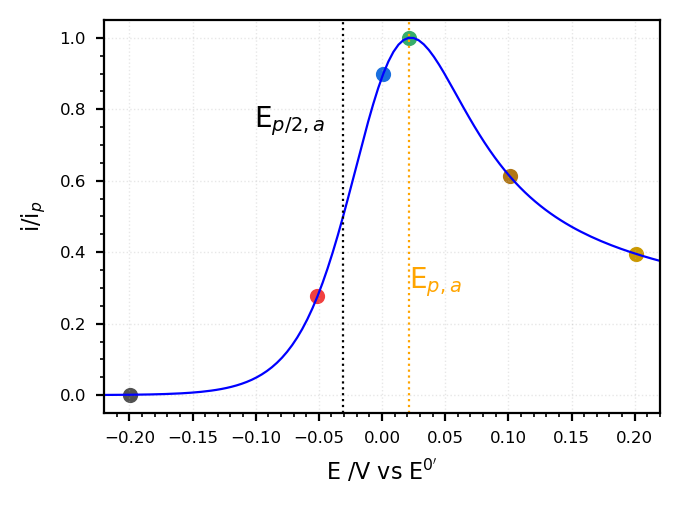

In [3]:
# The demonstration voltammogram, with its landmarks located FROM THE DATA.
demo_cv = np.genfromtxt('../Resources/data/demo_cv.csv', delimiter=',', skip_header=1)
demo_e = demo_cv[:, 0]
demo_i = demo_cv[:, 1]

# potentials at which students sketch the concentration profile
SELECTED_E = [-0.2, -0.05, 0.0, 0.021, 0.1, 0.2]

fig = plt.figure()
ax = plt.subplot()
landmarks = echem.annotate_demo_cv(ax, demo_e, demo_i, marked_potentials=SELECTED_E)

fig.savefig('../Workspace/lsv.png')
print(f"E_p,a   = {landmarks['e_peak_anodic']:+.3f} V")
print(f"E_p/2,a = {landmarks['e_half_peak']:+.3f} V")

#### Expected Behavior

The **Randles-Sevcik equation** (B&F Section 6.2) describes the peak current that is expected for a fully reversible electrochemical reaction that is probed under **semi-infinite diffusion conditions**:

$
\large i_p = 2.69x10^5 n^\frac{3}{2} A \sqrt{D_i \nu} C_i
$

Where $\nu$ is scan rate and all other variables have their common meaning. Tests for *electrochemical reversibility* may involve the shape of the observed peak. For example, at $T=25^oC$ it is expected that the spacing between the peak potential ( $E_{p,j}$ ) and the potential at half-peak height ( $E_{p/2}$ ) is:

$
\large E_p - E_\frac{p}{2} = \frac{56.5 mV}{n}
$

Notice that $n$ is a factor in determining peak shape!

<div class="alert alert-block alert-info">
<b>Activity:</b> Sketch the concentration profile that you would expect to see at each of the points marked on the figure above. Assume the initial solution contains only $R$ .
</div>

Reader beware: the facility with which a voltammetry experiment can be set up masks the complexity inherent in the technique. There are numerous considerations to generate clean data and make sense of the results you obtain. Perhaps most prominently, these considerations include:

1. Nature of the redox couple being analyzed. 
2. Electrolyte solution.
3. Working electrode. 
4. Experimental settings.
5. Process for extracting parameters.

Because of this hidden complexity, we will briefly review the concepts we have established:

#### Thermodynamics

The **Nernst equation** is the fundamental equation describing reaction thermodynamics for electron transfer reactions. Within the context of an electrochemical cell, this equation describes the equilibrium for an electrochemical reaction *at the electrode surface*:

\begin{equation}
\large E_{eq}(x=0,t) = E^{0'} + \frac{RT}{nF} \cdot ln(\frac{C_O(x=0)}{C_R(x=0)})
\end{equation} 

If we assume that both O and R have the same diffusion coefficients we can write (all $C_i$ are at x=0):

\begin{equation}
\large C_T = C_O + C_R
\end{equation}

\begin{equation}
\large 1 - \frac{C_R}{C_T} = \frac{C_O}{C_T}
\end{equation}

With substitution and rearrangement, the equation can be rewritten in exponential form to simplify visualization:

\begin{equation}
\large \frac{C_R}{C_T} = \frac{1}{1+e^{\frac{n F (E_{eq}(0,t) - E^{0'})}{RT}}}
\end{equation} 



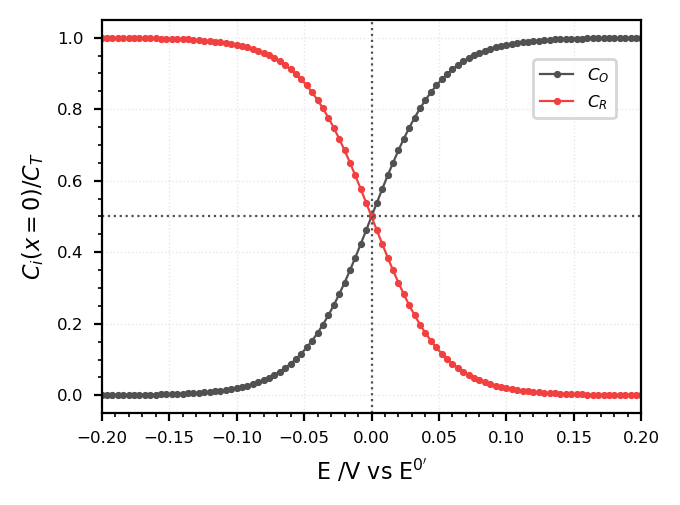

In [4]:
# Thermodynamics alone: the Nernst equation fixes the surface concentrations
conc_o_surface = echem.nernst_fraction_oxidized(POTENTIAL, n=N_ELECTRONS)
conc_r_surface = echem.nernst_fraction_reduced(POTENTIAL, n=N_ELECTRONS)

fig = plt.figure()
ax = plt.subplot()
ax.plot(POTENTIAL, conc_o_surface, '-o', label=r'$C_O$')
ax.plot(POTENTIAL, conc_r_surface, '-o', label=r'$C_R$')

ax.axhline(0.5, linestyle=':')
ax.axvline(0, linestyle=':')
ax.set_xlim(-0.2, 0.2)
ax.set_xlabel(r"E /V vs E$^{0'}$")
ax.set_ylabel(r'$C_i(x=0)/C_T$')
ax.legend(loc=(0.8, 0.75), fontsize=6)

# NOTE: save BEFORE showing.  plt.show() closes the figure, so a savefig placed
# after it writes a blank file.
fig.savefig('../Workspace/NernstEquation.png')

Key to thermodynamics is that application of an electrochemical potential to the working electrode forces the system to move from one equilibrium position to a new one. Thermodynamic arguments in electrochemistry are made with the understanding that the system being discussed is under equilibrium.

The transition from one equilibrium to another cannot occur instantly, requiring an understanding of **mass transfer** and **electron transfer kinetics**. The cyclic voltammetric experiment constantly sweeps $E_{eq}$ ; any valid interpretation must therefore consider the possible effects of both mass transfer and kinetics on the results. 

#### Mass Transfer

Mass transfer is the reason that we must specify $C_i(x=0)$ . The electron transfer reaction occurs only at the 2-dimensional electrode surface. This creates a concentration gradient for the reactant and product, inducing diffusion to/away from the electrode.

We will assume here that an anodic potential step is applied to a macrodisc electrode in a solution containing only the reduced form of a redox couple. Under such conditions we can describe the results using a **semi-infinite diffusion** approximation. Two different potential steps will be considered:
1. To a large oxidizing overpotential
2. To $E^{0'}$ 

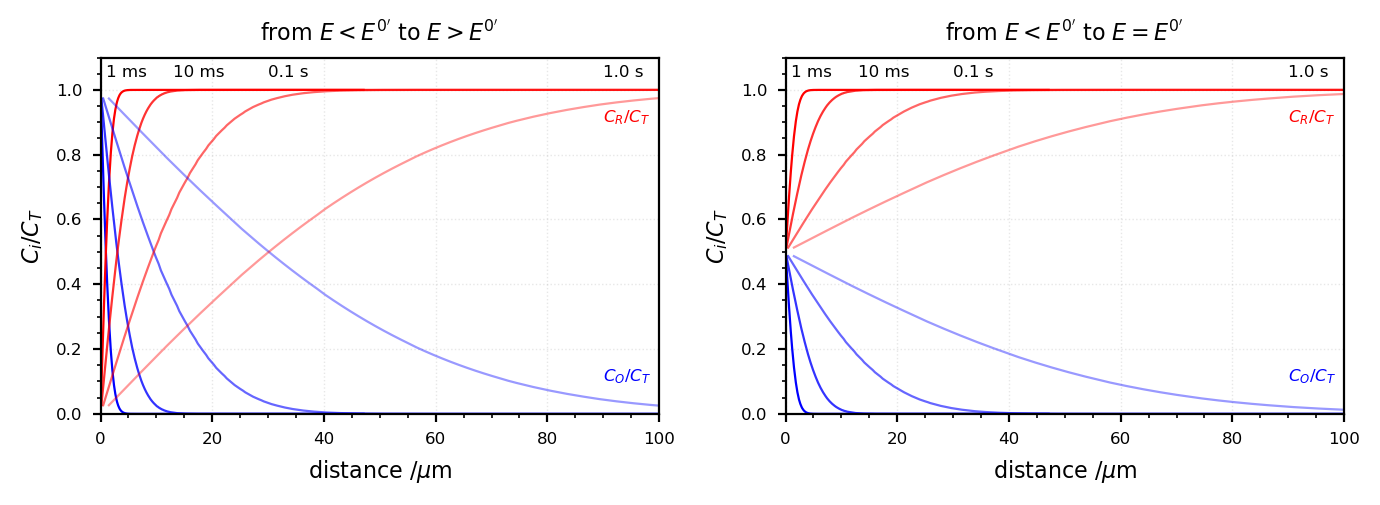

In [5]:
# Mass transport alone: the diffusion layer growing with time
demo_ca = np.genfromtxt('../Resources/data/diffusion_layer.csv', delimiter=',', skip_header=3)
ca_x = demo_ca[:, 1:5]*1e4          # cm -> micrometres
ca_co = demo_ca[:, 5]
ca_cr = demo_ca[:, 6]
ca_cr_half = ca_cr*0.5
ca_co_half = 1 - ca_cr_half

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax1.set_title(r"from $E<E^{0'}$ to $E>E^{0'}$")
ax2 = plt.subplot(122)
ax2.set_title(r"from $E<E^{0'}$ to $E=E^{0'}$")

fade = [1.0, 0.8, 0.6, 0.4]
for i in range(4):
    ax1.plot(ca_x[:, i], ca_cr, color='blue', alpha=fade[i])
    ax1.plot(ca_x[:, i], ca_co, color='red', alpha=fade[i])
    ax2.plot(ca_x[:, i], ca_cr_half, color='blue', alpha=fade[i])
    ax2.plot(ca_x[:, i], ca_co_half, color='red', alpha=fade[i])

for ax in [ax1, ax2]:
    for label, x in [('1 ms', 1), ('10 ms', 13), ('0.1 s', 30), ('1.0 s', 90)]:
        ax.annotate(label, (x, 1.04), fontsize=6)
    ax.annotate(r'$C_O/C_T$', (90, 0.1), color='blue', fontsize=6)
    ax.annotate(r'$C_R/C_T$', (90, 0.9), color='red', fontsize=6)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel(r'$C_i/C_T$')
    ax.set_xlim(0, 100)
    ax.set_xlabel(r'distance /$\mu$m')

fig.savefig('../Workspace/diffusionlayer.png')

Key to the figure above is that the concentration gradient expands into solution with time. This **diffusion layer** plays a critical role in establishing observed behavior in cyclic voltammetry. This role is captured through the **Cottrell Equation**:

\begin{equation}
\large i(t) = \frac{n F A C_i^* \sqrt{D_i}}{\sqrt{\pi t}}
\end{equation}


**Remember!** The diffusion layer is not to be confused with the electrochemical double layer! 

The **diffusion layer** is the volume extending away from the electrode surface in which the solution composition is not identical to that in the bulk; its size is dependent on the experiment time 

The **electrochemical double layer** is a structured layer of ions adjacent to the electrode surface; its size is determined by the ions in solution and is approximately static

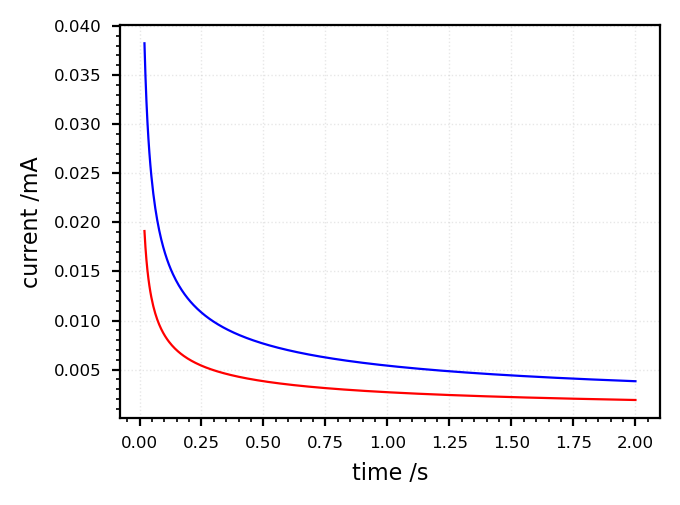

In [6]:
# Thermodynamics and transport together: the Cottrell decay at two potentials
i_driven = cottrell_current(0.5, TIME)      # far positive of E0': every arrival reacts
i_at_e0 = cottrell_current(0.0, TIME)       # at E0': only half of the couple is O

fig = plt.figure()
ax = plt.subplot()
ax.plot(TIME, i_driven*1000, 'blue')
ax.plot(TIME, i_at_e0*1000, 'red')
ax.annotate(r'E$^{0}$ + 0.5 V', (0.1, 1.), fontsize=6, color='blue')
ax.annotate(r'E$^{0}$', (0.1, 0.15), fontsize=6, color='red')
ax.annotate(r'$i \propto \frac{\sqrt{D_i}}{\sqrt{t}}$', (0.25, 0.5), fontsize=8)
ax.set_xlabel('time /s')
ax.set_ylabel('current /mA')

fig.savefig('../Workspace/Cottrell.png')

The Cottrell equation describes **mass transfer limited currents**. The magnitude of current that is observed is exclusively dictated by the flux of some species from bulk solution to the electroactive surface. As highlighted in the figure, the magnitude of observed currents are proportional to $\sqrt{D_i}$ and the decay is proportional to $1/\sqrt{t}$ . The faster the limiting species can move, the higher the observed currents.

#### Mass Transfer vs. Thermodynamics

This behavior is characteristic of any system held at a constant potential. The growth of the diffusion layer, and therefore the decay in current with time following Cottrell's equation, are dictated simply by **time** and the **diffusion coefficient** of the redox species. Sampled current voltammetry makes this generalized relationship obvious:

In [7]:
# Sampling the family of chronoamperograms at two times, as in Lesson 20.
TAU_1 = 0.3     # s
TAU_2 = 0.4     # s
sampled_current_1 = cottrell_current(POTENTIAL, TAU_1)
sampled_current_2 = cottrell_current(POTENTIAL, TAU_2)


@interact(tau_1=widgets.FloatText(step=0.02, value=TAU_1, description=r'$\tau_1$'),
          tau_2=widgets.FloatText(step=0.02, value=TAU_2, description=r'$\tau_2$'))
def plot_sampled_current(tau_1, tau_2):
    '''Sampling at a later time gives a smaller wave of exactly the same shape.'''
    if min(tau_1, tau_2) <= 0 or max(tau_1, tau_2) > TIME.max():
        print(f'Sampling times must lie between 0 and {TIME.max()} s.')
        return

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax1.set_title('Chronoamperometry')
    ax2 = plt.subplot(122)
    ax2.set_title('Sampled Current Voltammetry')

    for potential in POTENTIAL:
        ax1.plot(TIME, cottrell_current(potential, TIME)*1000)
    ax1.set_xlabel('time /s')
    ax1.set_ylabel('current /mA')
    ax1.set_xlim(0, 0.5)
    for tau, label, colour in [(tau_1, r'$\tau_1$', 'gray'), (tau_2, r'$\tau_2$', 'lightgray')]:
        ax1.axvline(tau, linestyle=':', color=colour)
        ax1.annotate(label, (tau + 0.01, 1.2), fontsize=6)
    ax1.annotate(r'+E', (0.05, 1.0), fontsize=6)

    for tau in [tau_1, tau_2]:
        ax2.plot(POTENTIAL, 1000*cottrell_current(POTENTIAL, tau),
                 label=rf'$\tau$ = {tau} s')
    ax2.set_xlim(-0.2, 0.2)
    ax2.set_xlabel(r"E /V vs E$^{0'}$")
    ax2.set_ylabel('i /mA')
    ax2.legend(fontsize=6, loc=2)

interactive(children=(FloatText(value=0.3, description='$\\tau_1$', step=0.02), FloatText(value=0.4, descripti…

#### Relevance to Cyclic Voltammetry
The basic structure of a cyclic voltammogram is established by both thermodynamics and mass transfer:
1. electrons are transferred at the surface to meet the new equilibrium imposed at the 2-dimensional electrode surface
2. a diffusion layer forms and is continually modified during the experiment

In [10]:
@interact(azim=widgets.FloatSlider(value=340, min=0, max=360, step=5, description='azimuth'),
          elev=widgets.FloatSlider(value=8, min=-90, max=90, step=5, description='elevation'))
def plot_current_surface(azim, elev):
    '''Every technique so far is a different path across ONE surface, i(E, t).

    Chronoamperometry holds E fixed and moves along t.
    Sampled current voltammetry holds t fixed and moves along E.
    Cyclic voltammetry moves along both at once, which is why it is so rich.
    '''
    # np.meshgrid(TIME, POTENTIAL) returns the TIME grid first.  Naming matters.
    time_grid, potential_grid = np.meshgrid(TIME, POTENTIAL)
    current_grid = 1000*cottrell_current(potential_grid, time_grid)

    fig = plt.figure(figsize=LARGE)
    ax = plt.subplot(projection='3d')
    ax.plot_wireframe(time_grid, potential_grid, current_grid,
                      rstride=2, cstride=5, color='black', alpha=0.3)

    # i vs E at a fixed time, projected onto the back wall
    ax.plot(POTENTIAL, 1000*sampled_current_1, zs=0., zdir='x', color='darkblue')
    ax.plot(POTENTIAL, 1000*sampled_current_2, zs=0., zdir='x', color='blue',
            label='sampled current voltammetry')

    # i vs t at a fixed potential, projected onto the side wall
    ax.plot(TIME, 1000*cottrell_current(0.5, TIME), zs=0.25, zdir='y', color='darkred')
    ax.plot(TIME, 1000*cottrell_current(0.0, TIME), zs=0.25, zdir='y', color='red',
            label='chronoamperometry')

    # the path a sweep traces across the floor
    ax.plot(TIME, -0.2 + TIME*0.2, zs=0, zdir='z', color='green',
            label='cyclic voltammetry')

    ax.set_xlabel('time /s')
    ax.set_ylabel(r"E /V vs E$^{0'}$")
    ax.set_zlabel('i /mA')
    ax.view_init(elev, azim)
    ax.set_xlim(TIME.min(), TIME.max())
    ax.set_ylim(POTENTIAL.min(), POTENTIAL.max())
    fig.legend(fontsize=6)

interactive(children=(FloatSlider(value=340.0, description='azimuth', max=360.0, step=5.0), FloatSlider(value=…

<div class="alert alert-block alert-danger">
<b>Memory Check:</b> The Randles-Sevcik equation says $i_p \propto \sqrt{\nu}$ . Which of the three pillars, thermodynamics, kinetics or mass transfer, puts the square root there, and why is it a square root rather than a linear dependence?
</div>

<div class="alert alert-block alert-info">
<b>Activity:</b> A linear sweep moves in two dimensions at once, $E$ and $t$ , while measuring a third.
<br>
Using the 3D surface above, explain in your own words why a <b>faster</b> sweep gives a <b>larger</b> peak current. Then predict what happens to the peak <i>potential</i> as the sweep rate increases, for a reversible couple and for an irreversible one.
</div>

- Why faster gives larger: ANSWER
- $E_p$ for a reversible couple: ANSWER
- $E_p$ for an irreversible couple: ANSWER